In [2]:
"""
Bristol Traffic Collisions – Data Cleaning, Feature Engineering & Visualisation
===============================================================================
Designed to display charts directly in Jupyter Notebook.
"""

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Optional: make plots display nicely in Jupyter
%matplotlib inline

# ---------------------------------------------------------------------------
# 0. Configuration
# ---------------------------------------------------------------------------
DATA_PATH = Path("Bristol Traffic Collisions.csv")  # adjust if needed
OUTPUT_DIR = Path("bristol_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# ---------------------------------------------------------------------------
# 1. LOAD DATA
# ---------------------------------------------------------------------------
print("1. Loading data...")
df = pd.read_csv(DATA_PATH)
print(f"   Loaded {len(df):,} records, {df.shape[1]} columns")

# ---------------------------------------------------------------------------
# 2. INITIAL QUALITY CHECK
# ---------------------------------------------------------------------------
print("\n2. Initial quality check")
print(f"   Missing values:\n{df.isnull().sum().to_string()}")
print(f"   Duplicate rows: {df.duplicated().sum()}")
print(f"   Date range: {df['DATE_'].min()} to {df['DATE_'].max()}")

# ---------------------------------------------------------------------------
# 3. DATETIME PARSING & FEATURE ENGINEERING
# ---------------------------------------------------------------------------
print("\n3. Creating temporal features...")

if "DATE_TIME_CONVERTED" in df.columns:
    df["datetime"] = pd.to_datetime(df["DATE_TIME_CONVERTED"], utc=True, errors="coerce")
else:
    df["datetime"] = pd.to_datetime(
        df["DATE_"] + " " + df["TIME"].astype(str).str.zfill(4),
        format="%Y/%m/%d %H%M", errors="coerce", utc=True
    )

df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["day_of_week"] = df["datetime"].dt.day_name()
df["hour"] = df["datetime"].dt.hour
df["is_weekend"] = df["datetime"].dt.dayofweek.isin([5, 6])
df["is_rush_hour"] = df["hour"].isin([7, 8, 9, 16, 17, 18])
df["vulnerable_user"] = (
    (df["PEDESTRIAN"] > 0) | (df["CYCLES"] > 0) | (df["MCYCLES"] > 0)
)

print(f"   Records with valid datetime: {df['datetime'].notna().sum():,}")

# ---------------------------------------------------------------------------
# 4. LIGHT CLEANING
# ---------------------------------------------------------------------------
print("\n4. Light cleaning...")
before = len(df)
df = df.dropna(subset=["datetime"]).copy()
print(f"   Dropped {before - len(df)} rows with invalid datetime")

severity_map = {1: "Fatal", 2: "Serious", 3: "Slight"}
df["severity_label"] = df["SEVERITY"].map(severity_map)

# ---------------------------------------------------------------------------
# 5. SAVE CLEANED DATA
# ---------------------------------------------------------------------------
cleaned_path = OUTPUT_DIR / "bristol_collisions_cleaned.csv"
df.to_csv(cleaned_path, index=False)
print(f"\n5. Cleaned data saved to: {cleaned_path}")
















1. Loading data...
   Loaded 4,093 records, 18 columns

2. Initial quality check
   Missing values:
OBJECTID                0
DATE_                   0
TIME                    0
SEVERITY                0
SEVERITY_DESCRIPTION    0
ACCIDENT_TYPE           0
ACCIDENT_DESCRIPTION    0
VEHICLES                0
CASUALTIES              0
PEDESTRIAN              0
CYCLES                  0
MCYCLES                 0
CHILDREN                0
OAPS                    0
X                       0
Y                       0
RENDER                  0
DATE_TIME_CONVERTED     0
   Duplicate rows: 0
   Date range: 2020/01/02 00:00:00+00 to 2024/12/31 00:00:00+00

3. Creating temporal features...
   Records with valid datetime: 4,093

4. Light cleaning...
   Dropped 0 rows with invalid datetime

5. Cleaned data saved to: bristol_outputs\bristol_collisions_cleaned.csv



6. Generating visualisations...



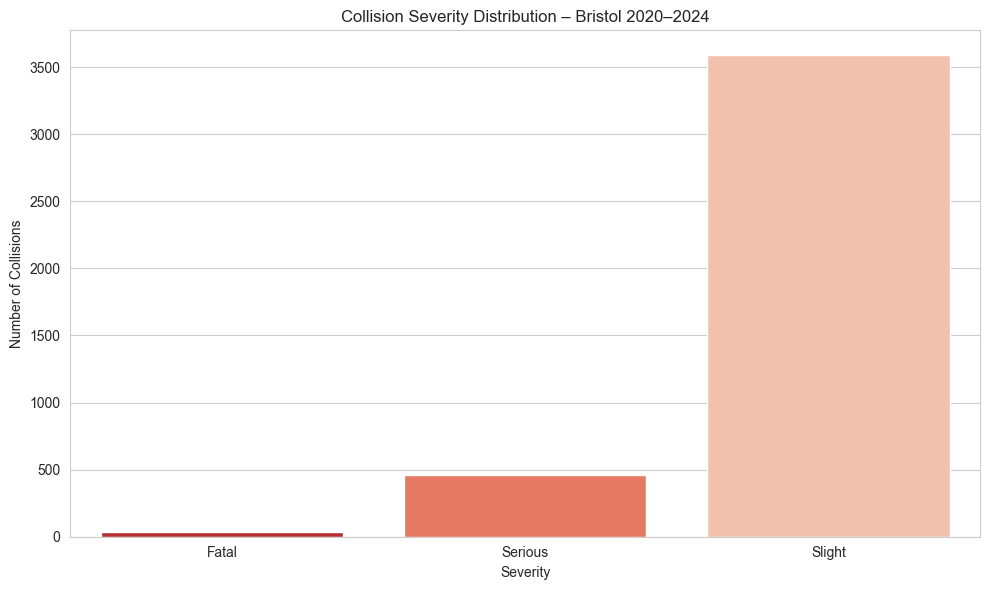

In [13]:
# ---------------------------------------------------------------------------
# 6. VISUALISATIONS 
# ---------------------------------------------------------------------------
print("\n6. Generating visualisations...\n")

# --- 6a. Severity distribution ---
fig, ax = plt.subplots()
order = ["Fatal", "Serious", "Slight"]
sns.countplot(
    data=df,
    x="severity_label",
    hue="severity_label",
    order=order,
    hue_order=order,
    palette="Reds_r",
    legend=False,
    ax=ax
)
ax.set_title("Collision Severity Distribution – Bristol 2020–2024")
ax.set_xlabel("Severity")
ax.set_ylabel("Number of Collisions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_severity_distribution.png", dpi=150)
plt.show()  # Display in notebook

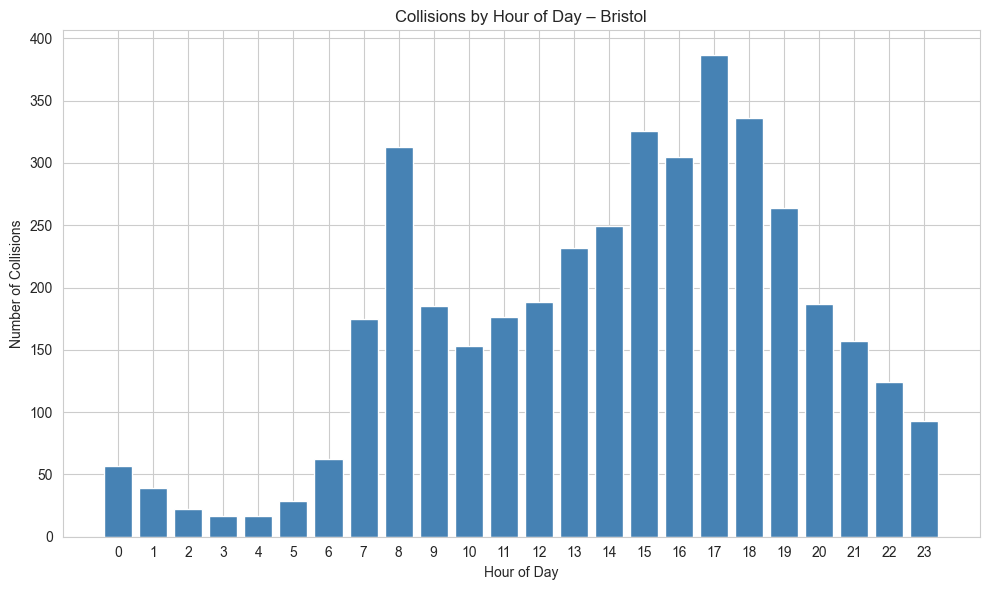

In [14]:
# --- 6b. Collisions by hour of day ---
fig, ax = plt.subplots()
hour_counts = df["hour"].value_counts().sort_index()
ax.bar(hour_counts.index, hour_counts.values, color="steelblue")
ax.set_title("Collisions by Hour of Day – Bristol")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Collisions")
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_collisions_by_hour.png", dpi=150)
plt.show()

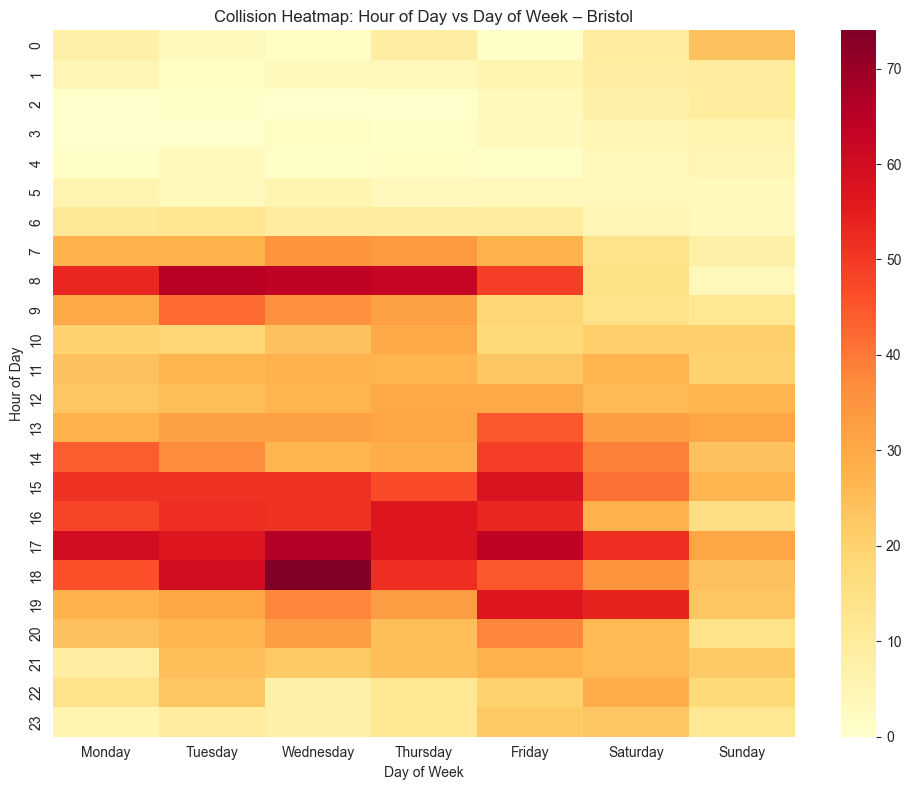

In [15]:
# --- 6c. Heatmap: Hour × Day of Week ---
heatmap_data = pd.crosstab(df["hour"], df["day_of_week"])
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heatmap_data = heatmap_data.reindex(columns=day_order)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(heatmap_data, cmap="YlOrRd", ax=ax)
ax.set_title("Collision Heatmap: Hour of Day vs Day of Week – Bristol")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Hour of Day")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_hour_day_heatmap.png", dpi=150)
plt.show()

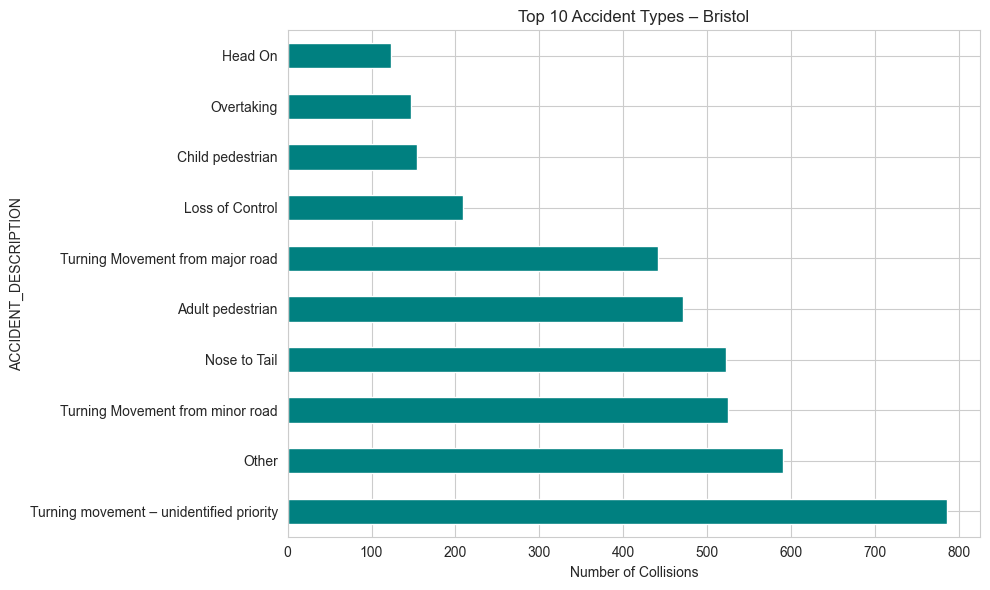

In [16]:
# --- 6d. Accident type breakdown ---
fig, ax = plt.subplots(figsize=(10, 6))
type_counts = df["ACCIDENT_DESCRIPTION"].value_counts().head(10)
type_counts.plot(kind="barh", ax=ax, color="teal")
ax.set_title("Top 10 Accident Types – Bristol")
ax.set_xlabel("Number of Collisions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_accident_types.png", dpi=150)
plt.show()

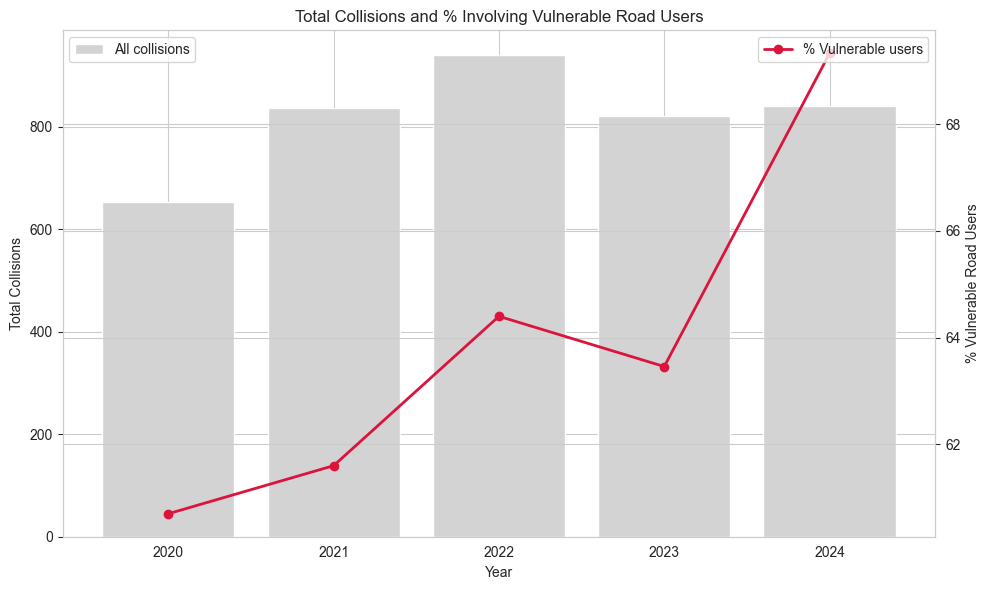

In [17]:
# --- 6e. Vulnerable road users over time ---
yearly = df.groupby("year").agg(
    total=("OBJECTID", "count"),
    vulnerable=("vulnerable_user", "sum")
).reset_index()
yearly["vulnerable_pct"] = yearly["vulnerable"] / yearly["total"] * 100

fig, ax1 = plt.subplots()
ax1.bar(yearly["year"], yearly["total"], color="lightgray", label="All collisions")
ax2 = ax1.twinx()
ax2.plot(yearly["year"], yearly["vulnerable_pct"], color="crimson", marker="o",
         linewidth=2, label="% Vulnerable users")
ax1.set_title("Total Collisions and % Involving Vulnerable Road Users")
ax1.set_xlabel("Year")
ax1.set_ylabel("Total Collisions")
ax2.set_ylabel("% Vulnerable Road Users")
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_vulnerable_users_trend.png", dpi=150)
plt.show()


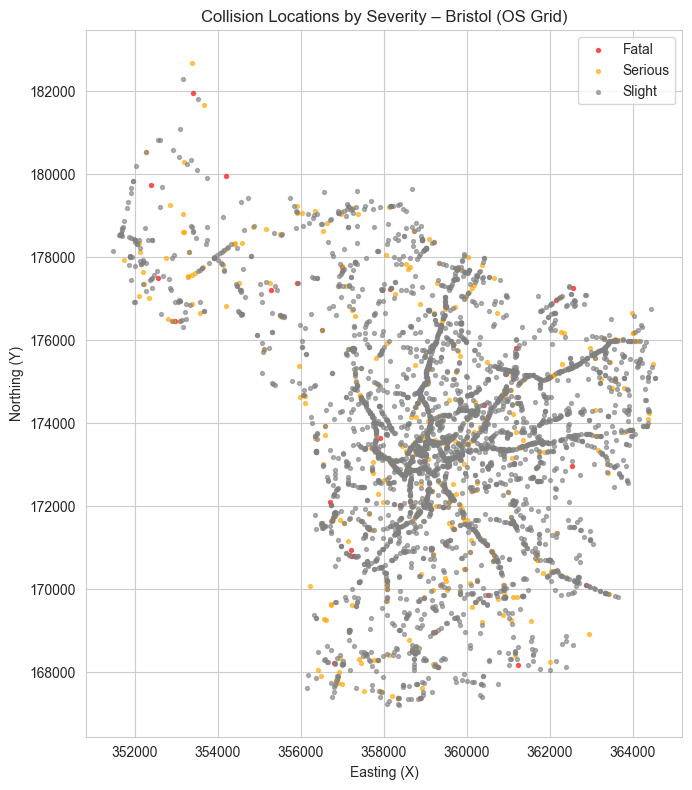

In [18]:
# --- 6f. Spatial overview (X/Y scatter) ---
fig, ax = plt.subplots(figsize=(8, 8))
severity_colors = {"Fatal": "red", "Serious": "orange", "Slight": "gray"}
for sev, color in severity_colors.items():
    subset = df[df["severity_label"] == sev]
    ax.scatter(subset["X"], subset["Y"], c=color, s=8, alpha=0.6, label=sev)
ax.set_title("Collision Locations by Severity – Bristol (OS Grid)")
ax.set_xlabel("Easting (X)")
ax.set_ylabel("Northing (Y)")
ax.legend()
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_spatial_severity.png", dpi=150)
plt.show()

In [19]:
# ---------------------------------------------------------------------------
# 7. SUMMARY STATISTICS
# ---------------------------------------------------------------------------
print("\n7. Summary statistics")
print(f"   Total collisions: {len(df):,}")
print(f"   Fatal: {(df['SEVERITY']==1).sum()}")
print(f"   Serious: {(df['SEVERITY']==2).sum()}")
print(f"   Slight: {(df['SEVERITY']==3).sum()}")
print(f"   % involving vulnerable users: {df['vulnerable_user'].mean()*100:.1f}%")
print(f"   Peak hour: {df['hour'].mode()[0]:02d}:00")

print("\nDone.")


7. Summary statistics
   Total collisions: 4,093
   Fatal: 36
   Serious: 463
   Slight: 3594
   % involving vulnerable users: 64.1%
   Peak hour: 17:00

Done.
